# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: /Users/loxxych/Documents/hse/3 курс/ММАД/Домашки/HW3/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        X_bias = np.column_stack([np.ones(len(X)), X])
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)
        self.w = np.zeros(X_bias.shape[1]) if self.w0 is None else np.asarray(self.w0, dtype=float).copy()
        self.stop_reason_ = 'max_iter'
        for _ in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X_bias, y))
            if self.gd_type == 'full':
                grad = self.calc_gradient(X_bias, y)
            elif self.gd_type == 'stochastic':
                idx = rng.choice(len(y), size=min(self.batch_size, len(y)), replace=False)
                grad = self.calc_gradient(X_bias[idx], y[idx])
            else:
                raise ValueError("gd_type должен быть 'full' или 'stochastic'")
            new_w = self.w - self.eta * grad
            diff = np.linalg.norm(new_w - self.w)
            self.w = new_w
            if diff < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break
        self.n_iter_ = len(self.loss_history)
        return self

    def sigmoid(self, z):
        z = np.asarray(z, dtype=float)
        result = np.empty_like(z)
        positive = z >= 0
        result[positive] = 1 / (1 + np.exp(-z[positive]))
        exp_z = np.exp(z[~positive])
        result[~positive] = exp_z / (1 + exp_z)
        return result

    def predict_proba(self, X):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        X = np.asarray(X, dtype=float)
        p = self.sigmoid(np.column_stack([np.ones(len(X)), X]) @ self.w)
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        p = self.sigmoid(X @ self.w)
        return X.T @ (p - y) / len(y)

    def calc_loss(self, X, y):
        p = np.clip(self.sigmoid(X @ self.w), 1e-15, 1 - 1e-15)
        return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 2.28e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

Full GD итераций: 1000 критерий: max_iter начальный loss: 0.6931 финальный loss: 0.5125
SGD итераций: 1000 критерий: max_iter начальный loss: 0.6931 финальный loss: 0.5129


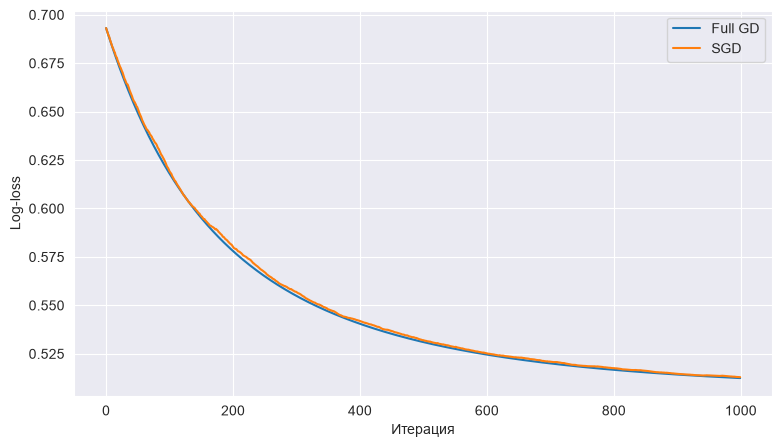

In [6]:
models_gd = {
    'Full GD': LogReg(gd_type='full').fit(X_train, y_train),
    'SGD': LogReg(gd_type='stochastic').fit(X_train, y_train)
}
for name, model in models_gd.items():
    print(name, 'итераций:', model.n_iter_, 'критерий:', model.stop_reason_, 'начальный loss:', round(model.loss_history[0], 4), 'финальный loss:', round(model.loss_history[-1], 4))
plt.figure(figsize=(9, 5))
for name, model in models_gd.items():
    plt.plot(model.loss_history, label=name)
plt.xlabel('Итерация')
plt.ylabel('Log-loss')
plt.legend()
plt.show()


На этих данных обе модели дошли до `max_iter=1000`, а не остановились по `tolerance`. Полный спуск использует все 14 000 объектов за шаг, SGD использует батч из 32 объектов. У SGD кривая более шумная, потому что градиент оценивается по случайной части данных. При постоянном шаге веса продолжают колебаться около минимума, поэтому норму разности весов трудно уменьшить до заданного tolerance.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

eta=0.001: loss=0.618141, итераций=1000


eta=0.01: loss=0.512451, итераций=1000


eta=0.1: loss=0.505762, итераций=465
eta=1: loss=0.505757, итераций=70


eta=10: loss=0.945807, итераций=1000


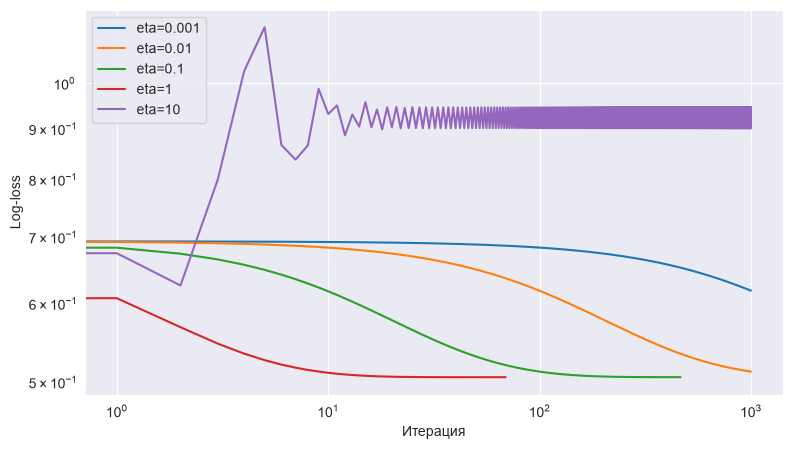

In [7]:
eta_results = {}
for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    model = LogReg(gd_type='full', eta=eta, max_iter=1000).fit(X_train, y_train)
    eta_results[eta] = model
    print(f'eta={eta}: loss={model.loss_history[-1]:.6f}, итераций={len(model.loss_history)}')
plt.figure(figsize=(9, 5))
for eta, model in eta_results.items():
    plt.plot(model.loss_history, label=f'eta={eta}')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Итерация')
plt.ylabel('Log-loss')
plt.legend()
plt.show()


Маленький шаг `eta=0.001` сходился медленно: loss 0.618 за 1000 итераций. При `0.01` loss стал 0.512 за 1000 итераций. Шаги `0.1` и `1` дали loss около 0.506 за 465 и 70 итераций. `eta=10` ведет себя плохо: loss остается высоким (около 0.946) и не сходится. Значит, увеличение шага ускоряет спуск до определенного предела, но слишком большой шаг мешает сходимости.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sk_model = LogisticRegression().fit(X_train, y_train)
sk_model_same = LogisticRegression(C=np.inf, max_iter=2000).fit(X_train, y_train)
own_gd = models_gd['Full GD']
comparison_gd = LogReg(gd_type='full', eta=0.1, max_iter=10000, tolerance=1e-8).fit(X_train, y_train)
own_sgd = models_gd['SGD']
score_rows = []
for name, model in [('Full GD', own_gd), ('SGD', own_sgd), ('sklearn', sk_model)]:
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    score_rows.append({'Модель': name, 'Accuracy': metrics.accuracy_score(y_test, pred), 'ROC-AUC': metrics.roc_auc_score(y_test, proba)})
display(pd.DataFrame(score_rows))
weights = pd.DataFrame({'LogReg GD': comparison_gd.w, 'sklearn': np.r_[sk_model.intercept_, sk_model.coef_.ravel()]}, index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])])
display(weights)
weights_same = pd.DataFrame({'LogReg GD': comparison_gd.w, 'sklearn без регуляризации': np.r_[sk_model_same.intercept_, sk_model_same.coef_.ravel()]}, index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])])
display(weights_same)


,Модель,Accuracy,ROC-AUC
0,Full GD,0.7820,0.838787
1,SGD,0.7825,0.838115
2,sklearn,0.7765,0.838676


,LogReg GD,sklearn
intercept,-0.022163,-0.021880
x0,0.002762,0.002741
x1,0.008962,0.009039
x2,-0.723248,-0.722690
x3,-0.262775,-0.262335
x4,0.016537,0.016588
x5,-0.011549,-0.011488
x6,0.005580,0.005587
x7,0.057240,0.057188
x8,-0.001201,-0.001239


,LogReg GD,sklearn без регуляризации
intercept,-0.022163,-0.021928
x0,0.002762,0.002734
x1,0.008962,0.009044
x2,-0.723248,-0.723222
x3,-0.262775,-0.262635
x4,0.016537,0.016600
x5,-0.011549,-0.011503
x6,0.005580,0.005599
x7,0.057240,0.057241
x8,-0.001201,-0.001236


На синтетических данных метрики трех моделей близки: Full GD дает accuracy 0.782 и ROC-AUC 0.839, SGD 0.783 и 0.838, sklearn с настройками по умолчанию 0.777 и 0.839. Веса GD и стандартной модели sklearn немного различаются. В документации сказано, что sklearn по умолчанию использует L2-регуляризацию. Чтобы убрать штраф и сравнить ту же задачу, я обучил модель с `C=np.inf`; ее веса почти совпали с сошедшимся полным GD.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Исходная форма:', df.shape)
duplicate_count = int(df.duplicated().sum())
print('Полных дубликатов до очистки:', duplicate_count)
df.head()

Исходная форма: (6497, 13)
Полных дубликатов до очистки: 1177


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
df = df.drop_duplicates().reset_index(drop=True)
print('Форма после удаления полных дубликатов:', df.shape)
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Форма после удаления полных дубликатов: (5320, 13)
Train: (3724, 12)  Test: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
print('Пропуски:', int(df.isna().sum().sum()))
print('Полных дубликатов до очистки:', duplicate_count)
print('Доля класса 1 train:', y_train.mean())
print('Доля класса 1 test:', y_test.mean())
constant_accuracy = (y_test == 0).mean()
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
pipe.fit(X_train, y_train)
pipe_accuracy = metrics.accuracy_score(y_test, pipe.predict(X_test))
print('Accuracy константной модели:', constant_accuracy)
print('Accuracy логистической регрессии:', pipe_accuracy)


Пропуски: 0
Полных дубликатов до очистки: 1177
Доля класса 1 train: 0.1895810955961332
Доля класса 1 test: 0.18984962406015038
Accuracy константной модели: 0.8101503759398496
Accuracy логистической регрессии: 0.8151629072681704


В данных не было пропусков, но нашлось 1177 полных дубликатов. Я удалил точные повторы до разбиения, иначе одинаковые строки могли оказаться и в train, и в test и завысить качество. После удаления осталось 5320 строк. Доля класса 1 близкая: около 0.190 в train и test благодаря `stratify=y`. Константная модель получает accuracy 0.810, а логистическая регрессия 0.815. Разница мала, потому что класс 0 преобладает; accuracy почти не показывает, насколько хорошо находятся хорошие вина.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP, TN, FP, FN: 92 1209 84 211
[[1209   84]
 [ 211   92]]


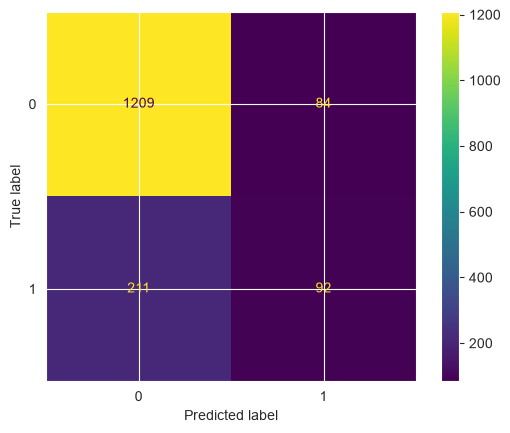

In [12]:
y_pred = pipe.predict(X_test)
tp = int(((y_test == 1) & (y_pred == 1)).sum())
tn = int(((y_test == 0) & (y_pred == 0)).sum())
fp = int(((y_test == 0) & (y_pred == 1)).sum())
fn = int(((y_test == 1) & (y_pred == 0)).sum())
print('TP, TN, FP, FN:', tp, tn, fp, fn)
print(metrics.confusion_matrix(y_test, y_pred))
metrics.ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()


FP здесь означает, что посредственное вино ошибочно включено в подборку; FN означает, что хорошее вино пропущено. FN больше: 211 против 84 FP. Значит, при стандартном пороге модель чаще не замечает хорошие вина.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
def fbeta(beta):
    return (1 + beta ** 2) * precision * recall / (beta ** 2 * precision + recall) if beta ** 2 * precision + recall else 0
print({'precision': precision, 'recall': recall, 'F1': fbeta(1), 'F0.5': fbeta(0.5), 'F2': fbeta(2)})
print('sklearn:', metrics.precision_score(y_test, y_pred, zero_division=0), metrics.recall_score(y_test, y_pred, zero_division=0), metrics.fbeta_score(y_test, y_pred, beta=1, zero_division=0), metrics.fbeta_score(y_test, y_pred, beta=0.5, zero_division=0), metrics.fbeta_score(y_test, y_pred, beta=2, zero_division=0))


{'precision': 0.5227272727272727, 'recall': 0.30363036303630364, 'F1': 0.384133611691023, 'F0.5': 0.45680238331678247, 'F2': 0.3314121037463976}
sklearn: 0.5227272727272727 0.30363036303630364 0.38413361169102295 0.4568023833167825 0.3314121037463977


Расчеты по формулам совпали со sklearn: precision 0.523, recall 0.304, F1 0.384, F0.5 0.457 и F2 0.331. В F0.5 сильнее ценится precision, в F2 recall. Для подписчиков, чувствительных к посредственным винам, я бы выбрал F0.5; для самой широкой подборки хороших вин лучше F2.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

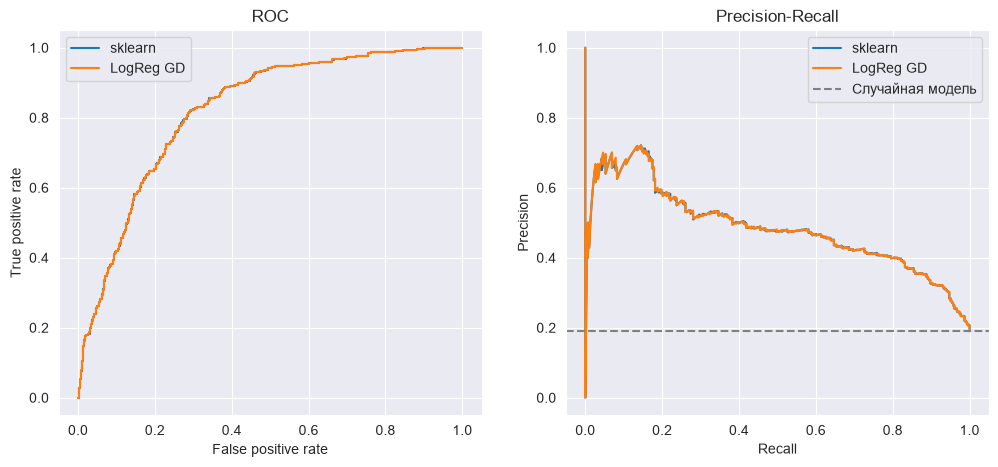

,Модель,ROC-AUC,PR-AUC
0,sklearn,0.820876,0.484766
1,LogReg GD,0.820822,0.484745


10*p 0.8208760551229137
p^3 0.8208760551229137
logit 0.8208760551229137
-p 0.17912394487708633


In [14]:
roc_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
roc_model.fit(X_train, y_train)
logreg_gd = make_pipeline(StandardScaler(), LogReg(gd_type='full', eta=0.1, max_iter=10000, tolerance=1e-7))
logreg_gd.fit(X_train, y_train)
sc_models = {'sklearn': roc_model, 'LogReg GD': logreg_gd}
sc_scores = {name: model.predict_proba(X_test)[:, 1] for name, model in sc_models.items()}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, score in sc_scores.items():
    fpr, tpr, _ = metrics.roc_curve(y_test, score)
    prec, rec, _ = metrics.precision_recall_curve(y_test, score)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(rec, prec, label=name)
axes[1].axhline(y_test.mean(), linestyle='--', color='gray', label='Случайная модель')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall')
for ax in axes:
    ax.legend()
plt.show()
auc_table = pd.DataFrame([{'Модель': name, 'ROC-AUC': metrics.roc_auc_score(y_test, score), 'PR-AUC': metrics.average_precision_score(y_test, score)} for name, score in sc_scores.items()])
display(auc_table)
p = sc_scores['sklearn']
p_safe = np.clip(p, 1e-15, 1 - 1e-15)
for name, transformed in {'10*p': 10*p, 'p^3': p**3, 'logit': np.log(p_safe/(1-p_safe)), '-p': -p}.items():
    print(name, metrics.roc_auc_score(y_test, transformed))


На тесте ROC-AUC и PR-AUC двух моделей очень близки: sklearn дает 0.8209 и 0.4848, свой GD 0.8208 и 0.4847. Ранжирование моделей по этим метрикам совпадает. Для `10*p`, `p^3` и logit ROC-AUC остается 0.8209, потому что возрастающее преобразование сохраняет порядок оценок. Для `-p` порядок разворачивается, ROC-AUC становится 0.1791. PR-AUC случайной модели равен доле положительного класса, около 0.190, а не 0.5. Если подать в ROC-AUC бинарные предсказания, получится значение balanced accuracy для выбранного порога 0.5, а не оценка всего ранжирования.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

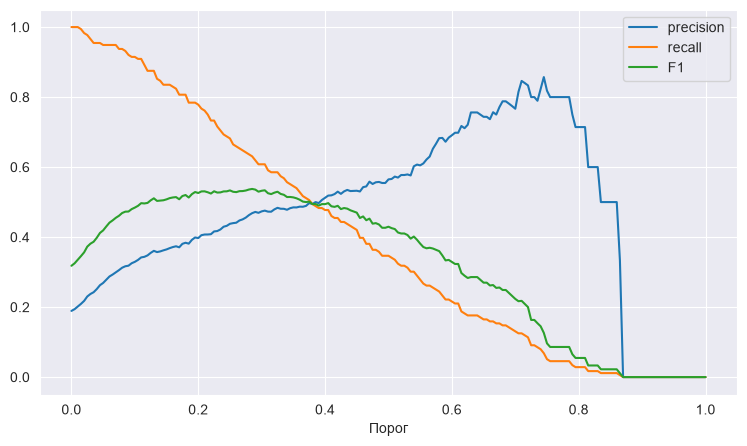

,Порог,Precision,Recall,F1
0,0.500,0.522727,0.303630,0.384134
1,0.285,0.457831,0.627063,0.529248
2,0.235,0.422397,0.709571,0.529557


t_F1: 0.28500000000000003 t_R: 0.23500000000000001


In [15]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)
val_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
val_model.fit(X_fit, y_fit)
val_prob = val_model.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0, 1, 201)
rows = []
for t in thresholds:
    pred = val_prob >= t
    rows.append((t, metrics.precision_score(y_val, pred, zero_division=0), metrics.recall_score(y_val, pred, zero_division=0), metrics.f1_score(y_val, pred, zero_division=0)))
threshold_df = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'F1'])
t_f1 = threshold_df.loc[threshold_df.F1.idxmax(), 'threshold']
valid_recall = threshold_df[threshold_df.recall >= 0.7]
t_r = valid_recall.loc[valid_recall.precision.idxmax(), 'threshold']
threshold_df.set_index('threshold')[['precision', 'recall', 'F1']].plot(figsize=(9, 5))
plt.xlabel('Порог')
plt.show()
roc_model.fit(X_train, y_train)
test_prob = roc_model.predict_proba(X_test)[:, 1]
test_rows = []
for t in [0.5, t_f1, t_r]:
    pred = test_prob >= t
    test_rows.append({'Порог': t, 'Precision': metrics.precision_score(y_test, pred, zero_division=0), 'Recall': metrics.recall_score(y_test, pred, zero_division=0), 'F1': metrics.f1_score(y_test, pred, zero_division=0)})
display(pd.DataFrame(test_rows))
print('t_F1:', t_f1, 't_R:', t_r)


На валидации получились `t_F1=0.285` и `t_R=0.235`. На тесте при пороге 0.5 precision=0.523, recall=0.304, F1=0.384; при `t_F1` это 0.458, 0.627 и 0.529; при `t_R` это 0.422, 0.710 и 0.530. На test recall едва выше требуемых 0.7. Порог не гарантирует recall на новых данных, потому что валидационная и будущая выборки отличаются. Для широкой подборки выбрал бы `t_R`; для более строгого отбора нужен более высокий порог и больший акцент на precision.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
class_models = {}
for weight in [None, 'balanced']:
    model = make_pipeline(StandardScaler(), LogisticRegression(class_weight=weight, max_iter=2000, random_state=RANDOM_STATE))
    model.fit(X_train, y_train)
    class_models[str(weight)] = model

weight_results = {}
for name, model in class_models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    weight_results[name] = {'Accuracy': metrics.accuracy_score(y_test, pred), 'Precision': metrics.precision_score(y_test, pred, zero_division=0), 'Recall': metrics.recall_score(y_test, pred, zero_division=0), 'F1': metrics.f1_score(y_test, pred, zero_division=0), 'ROC-AUC': metrics.roc_auc_score(y_test, prob), 'PR-AUC': metrics.average_precision_score(y_test, prob)}
display(pd.DataFrame(weight_results).T)
counts = y_train.value_counts()
print('Веса классов balanced:', {int(c): len(y_train) / (len(counts) * n) for c, n in counts.items()})


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
None,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
balanced,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147


Веса классов balanced: {0: 0.6169648774022531, 1: 2.6373937677053823}


Balanced веса по формуле равны примерно 0.617 для класса 0 и 2.637 для класса 1. Recall вырос с 0.304 до 0.785, precision упал с 0.523 до 0.399, accuracy с 0.815 до 0.734. ROC-AUC почти не поменялся: 0.821 против 0.821; PR-AUC тоже почти тот же, 0.485 против 0.481. Вес класса 1 повышает склонность модели его предсказывать, поэтому recall растет, а ложных рекомендаций становится больше.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.pipeline import make_pipeline as make_imblearn_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {'UnderSampler': RandomUnderSampler(random_state=RANDOM_STATE), 'NearMiss v2': NearMiss(version=2), 'OverSampler': RandomOverSampler(random_state=RANDOM_STATE), 'SMOTE': SMOTE(random_state=RANDOM_STATE)}
resample_models = {}
resample_metrics = {}
for name, sampler in samplers.items():
    model = make_imblearn_pipeline(StandardScaler(), sampler, LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    model.fit(X_train, y_train)
    resample_models[name] = model
    y_res = model[1].fit_resample(model[0].transform(X_train), y_train)[1]
    print(name, pd.Series(y_res).value_counts().sort_index().to_dict())
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    resample_metrics[name] = {'Accuracy': metrics.accuracy_score(y_test, pred), 'Precision': metrics.precision_score(y_test, pred, zero_division=0), 'Recall': metrics.recall_score(y_test, pred, zero_division=0), 'F1': metrics.f1_score(y_test, pred, zero_division=0), 'ROC-AUC': metrics.roc_auc_score(y_test, prob), 'PR-AUC': metrics.average_precision_score(y_test, prob)}

display(pd.DataFrame({**weight_results, **resample_metrics}).T)
print('Лучший и худший методы по PR-AUC:', sorted({name: metrics.average_precision_score(y_test, model.predict_proba(X_test)[:, 1]) for name, model in resample_models.items()}.items(), key=lambda item: item[1])[-1], sorted({name: metrics.average_precision_score(y_test, model.predict_proba(X_test)[:, 1]) for name, model in resample_models.items()}.items(), key=lambda item: item[1])[0])
scaled_first = make_imblearn_pipeline(StandardScaler(), SMOTE(random_state=RANDOM_STATE), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
resample_first = make_imblearn_pipeline(SMOTE(random_state=RANDOM_STATE), StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
scaled_first.fit(X_train, y_train)
resample_first.fit(X_train, y_train)
print('PR-AUC: scale -> SMOTE:', metrics.average_precision_score(y_test, scaled_first.predict_proba(X_test)[:, 1]), 'SMOTE -> scale:', metrics.average_precision_score(y_test, resample_first.predict_proba(X_test)[:, 1]))


UnderSampler {0: 706, 1: 706}


NearMiss v2 {0: 706, 1: 706}
OverSampler {0: 3018, 1: 3018}
SMOTE {0: 3018, 1: 3018}


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
None,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
balanced,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
UnderSampler,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
NearMiss v2,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
OverSampler,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
SMOTE,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606


Лучший и худший методы по PR-AUC: ('OverSampler', 0.4810772864941705) ('NearMiss v2', 0.44790275172778743)
PR-AUC: scale -> SMOTE: 0.47960633126147867 SMOTE -> scale: 0.4851522428244597


`imblearn`-пайплайн ресемплирует только тренировочные данные; на test при predict применяется только преобразование и классификатор. Если балансировать до разделения, тест перестанет отражать реальную долю классов и появится утечка данных. Лучший из проверенных по PR-AUC - RandomOverSampler (0.481), худший - NearMiss v2 (0.448). NearMiss и SMOTE используют расстояния между объектами, поэтому масштаб признаков влияет на соседей; для них логично сначала масштабировать. Перестановка шагов у SMOTE изменила PR-AUC примерно с 0.480 до 0.485, в этом запуске чуть лучше оказалось ресемплирование до scaler. Это конкретный результат данного набора, а не гарантия: масштабирование перед поиском соседей обычно делает расстояние более осмысленным. RandomUnderSampler и RandomOverSampler выбирают/копируют строки случайно, поэтому сам выбор объектов от масштаба не зависит, хотя scaler после ресемплинга рассчитает другие статистики.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

PR-AUC balanced: 0.48114695873979124 PR-AUC без весов: 0.48476554851347986


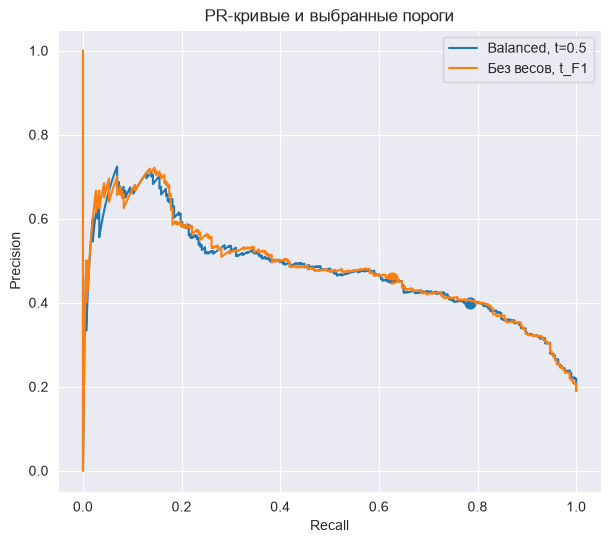

In [18]:
balanced_model = class_models['balanced']
plain_model = class_models['None']
prob_bal = balanced_model.predict_proba(X_test)[:, 1]
prob_plain = plain_model.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(figsize=(7, 6))
for name, prob, threshold in [('Balanced, t=0.5', prob_bal, 0.5), ('Без весов, t_F1', prob_plain, t_f1)]:
    prec_curve, rec_curve, ts = metrics.precision_recall_curve(y_test, prob)
    ax.plot(rec_curve, prec_curve, label=name)
    pred = prob >= threshold
    ax.scatter(metrics.recall_score(y_test, pred, zero_division=0), metrics.precision_score(y_test, pred, zero_division=0), s=60)
print('PR-AUC balanced:', metrics.average_precision_score(y_test, prob_bal), 'PR-AUC без весов:', metrics.average_precision_score(y_test, prob_plain))
ax.set(xlabel='Recall', ylabel='Precision', title='PR-кривые и выбранные пороги')
ax.legend()
plt.show()


PR-AUC без весов 0.485, с весами 0.481, поэтому кривые и ранжирование близки. При пороге 0.5 balanced-модель дает recall 0.785 и precision 0.399, заметно сдвигая рабочую точку к более широкому отбору. Это похоже на сдвиг порога, хотя сами вероятности и кривая тоже немного меняются.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
all_models = {'LogReg sklearn': roc_model, 'LogReg GD': logreg_gd, 'Class weight balanced': balanced_model, **resample_models}
def evaluate_model(model):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    return {'Accuracy': metrics.accuracy_score(y_test, pred), 'Precision': metrics.precision_score(y_test, pred, zero_division=0), 'Recall': metrics.recall_score(y_test, pred, zero_division=0), 'F1': metrics.f1_score(y_test, pred, zero_division=0), 'ROC-AUC': metrics.roc_auc_score(y_test, prob), 'PR-AUC': metrics.average_precision_score(y_test, prob)}
all_metrics = pd.DataFrame({name: evaluate_model(model) for name, model in all_models.items()}).T
tuned_pred = prob_plain >= t_r
all_metrics.loc['Без весов, t_R'] = {'Accuracy': metrics.accuracy_score(y_test, tuned_pred), 'Precision': metrics.precision_score(y_test, tuned_pred, zero_division=0), 'Recall': metrics.recall_score(y_test, tuned_pred, zero_division=0), 'F1': metrics.f1_score(y_test, tuned_pred, zero_division=0), 'ROC-AUC': metrics.roc_auc_score(y_test, prob_plain), 'PR-AUC': metrics.average_precision_score(y_test, prob_plain)}
display(all_metrics)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
LogReg sklearn,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
LogReg GD,0.815163,0.522727,0.303630,0.384134,0.820822,0.484745
Class weight balanced,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
UnderSampler,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
NearMiss v2,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
OverSampler,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
SMOTE,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606
"Без весов, t_R",0.760652,0.422397,0.709571,0.529557,0.820876,0.484766


Для широкой подборки я бы предложил обычную логистическую регрессию с `t_R=0.235`, найденным на валидации. На тесте она дает recall 0.710, precision 0.422 и F1 0.530, то есть находит требуемую долю хороших вин, но добавляет ложные рекомендации. Если клиенты особенно не любят посредственные вина, нужно повысить порог и принять более низкий recall.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = plain_model
final_threshold = t_r
joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

Ссылка на опубликованное приложение: https://mmda-hw3-loxxych.streamlit.app/

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

**Использование ИИ:**

При выполнении задания использовался Codex для подготовки кода и формулировки части ответов. Ячейки ноутбука выполнены, результаты сохранены.